# 08 · Own pipeline, part 3: a stronger RT-DETR

Notebook 07 showed that the pipeline is limited by its strongest member: flip TTA, the ensemble and
temporal rescoring together add +0.017 val mAP to RT-DETR (0.256 → 0.273). Two earlier results point to
how the model itself can improve:

| Earlier result | Change here |
|---|---|
| RT-DETR's val mAP peaked after 1–2 of 8 epochs on every 10th training frame (notebook 05): the model sees the same 2,446 frames again and again | **3.4× more distinct frames**: every 3rd training frame (about 8,100), 4 epochs |
| Small objects are the weakest point (AP_small 0.145 vs AP_large 0.44); none of the 3,811 test frames is wider than 2000 px, but the 800 × 1333 input still shrinks a 1920 × 1080 frame | **input 1080 × 1920**: test frames keep their full size, 4K frames are shrunk 2× instead of 2.9× |
| One strong model limits the ensemble (Faster R-CNN and FCOS made it worse, notebook 07) | **RT-DETRv2** (Lv et al., 2024, Baidu): same design with an improved decoder and training recipe, as a second strong member |

Each change is one run, so its effect is measured on its own:

| run | training frames | input | model | GPU time |
|---|---|---|---|---|
| `rtdetr_baseline` (notebook 05) | every 10th, 8 epochs | 800 × 1333 | RT-DETR R50vd | 1.3 h |
| `rtdetr_data3` | every 3rd, 4 epochs | 800 × 1333 | RT-DETR R50vd | ~2.5 h |
| `rtdetr_hires` | every 3rd, 4 epochs | 1080 × 1920 | RT-DETR R50vd | ~5 h |
| `rtdetr_v2` | every 3rd, 4 epochs | the better of the two | RT-DETRv2 R50vd | ~3–5 h |

All runs use the same validation protocol as before (full val split, pycocotools with ignored regions).
The runs take longer than one Kaggle session allows, so the notebook is run in several sessions: each
session gets a time budget, training stops at an epoch boundary before the budget ends, and the next
session (with the previous output attached as input) continues from the last epoch.

## Setup

In [1]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-object-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwdet import env
from hwdet.data.download import ensure_data
from hwdet.tracker import Run, status
P = env.setup(seed=42)
ensure_data(P, drive_cache=False)   # Colab: the zip goes to the local disk, not Drive
status(P)                           # which runs / stages are already done

platform: kaggle
    data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
 outputs: /kaggle/working/outputs
   cache: /tmp/hwdet_cache
    repo: /kaggle/working/repo
  device: cuda
data ready at /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


""


In [2]:
# Imports, plot style, W&B login, time budget of this session
import time
import pandas as pd
import matplotlib.pyplot as plt
import torch

from hwdet.config import load_config
from hwdet.data.detection_dataset import build_targets
from hwdet.data.io import frame_table
from hwdet.engine import Data, run_experiment
from hwdet.env import REPO_ROOT
from hwdet.rtdetr import build_rtdetr
from hwdet.viz import save_fig, set_style
from hwdet.wandb_utils import login_from_secrets

SESSION_HOURS = 5.0                      # GPU hours this session may use (Kaggle quota left minus a margin)
NOTEBOOK_START = time.time()
STOP_AT = NOTEBOOK_START + SESSION_HOURS * 3600
set_style()
login_from_secrets()
print("torch", torch.__version__, "| device", env.device(), f"| time budget {SESSION_HOURS} h")

no WANDB_API_KEY found: runs are tracked locally only
torch 2.11.0+cu130 | device cuda | time budget 5.0 h


## 1. Data

In [3]:
# Every 3rd training frame (new) next to every 10th (notebooks 02-05); full val, every 5th val frame to monitor
cfg = load_config("rtdetr_data3")
all_train = frame_table(P.data, "train")
train10 = all_train[(all_train.frame - 1) % 10 == 0]
train3 = all_train[(all_train.frame - 1) % cfg["split"]["train_frame_step"] == 0]
val_frames = frame_table(P.data, "val")
monitor_frames = val_frames[(val_frames.frame - 1) % cfg["split"]["monitor_frame_step"] == 0]
test_frames = frame_table(P.data, "test")
targets = build_targets(P.data, pd.concat([train3, train10, val_frames]).drop_duplicates("file_name"))
data = Data(P.data, train3, val_frames, monitor_frames, targets, test_frames)
n_obj = {fn: len(t["boxes"]) for fn, t in targets.items()}
pd.DataFrame({"frames": [len(train10), len(train3), len(val_frames), len(test_frames)],
              "objects": [sum(n_obj.get(f, 0) for f in d.file_name) for d in (train10, train3, val_frames)] + [None],
              "widest frame, px": [d.width.max() for d in (train10, train3, val_frames, test_frames)]},
             index=["train, every 10th", "train, every 3rd", "val", "test"])

,frames,objects,"widest frame, px"
"train, every 10th",2446,112264.0,2720
"train, every 3rd",8090,370072.0,2720
val,2846,114132.0,3840
test,3811,NaN,1920


## 2. Model check

Every architecture used below is built once on the CPU before any training starts, so a wrong checkpoint
name or an incompatible library version shows up in the first minutes instead of after hours of training.

In [4]:
# Build each model once (COCO weights + new 8-class heads) and count its parameters
for name in ("rtdetr_data3", "rtdetr_v2"):
    c = load_config(name)
    m = build_rtdetr(c)
    print(f"{name}: {c['model']['arch']}, {sum(p.numel() for p in m.parameters()) / 1e6:.1f} M parameters")
    del m

rtdetr_data3: PekingU/rtdetr_r50vd, 42.7 M parameters
rtdetr_v2: PekingU/rtdetr_v2_r50vd, 42.7 M parameters


## 3. Runs

Each cell trains one config, evaluates the best epoch on the full val split, predicts the test set and
writes a submission file. A cell whose run is finished only prints its metrics; a cell reached after the
time budget prints that it was postponed.

In [5]:
# Run 1: every 3rd training frame (3.4x more distinct frames), 4 epochs, input 800 x 1333 as in notebook 05
runs = {}
runs["rtdetr_data3"] = run_experiment("rtdetr_data3", build_rtdetr, P, data, predict_test=True,
                                      stop_at=STOP_AT, eval_hours=0.6)

run 'rtdetr_data3' at /kaggle/working/outputs/runs/rtdetr_data3  done: nothing yet
epoch 0: loss_vfl=4.01, loss_bbox=0.792, loss_giou=5.102, dn_loss_vfl=3.282, dn_loss_bbox=0.3752, dn_loss_giou=3.364, lr=8.545e-06, train_min=32.7, val_mAP=0.2542, val_AP50=0.4884, val_AP_small=0.1533
epoch 1: loss_vfl=3.601, loss_bbox=0.4253, loss_giou=3.864, dn_loss_vfl=2.569, dn_loss_bbox=0.301, dn_loss_giou=2.919, lr=5.016e-06, train_min=32.59, val_mAP=0.2629, val_AP50=0.503, val_AP_small=0.143
epoch 2: loss_vfl=3.4, loss_bbox=0.3824, loss_giou=3.634, dn_loss_vfl=2.468, dn_loss_bbox=0.279, dn_loss_giou=2.769, lr=1.477e-06, train_min=32.71, val_mAP=0.2536, val_AP50=0.4876, val_AP_small=0.1355
epoch 3: loss_vfl=3.31, loss_bbox=0.366, loss_giou=3.521, dn_loss_vfl=2.427, dn_loss_bbox=0.27, dn_loss_giou=2.694, lr=3.772e-11, train_min=32.7, val_mAP=0.2561, val_AP50=0.4884, val_AP_small=0.1245
submission looks valid
wrote /kaggle/working/outputs/runs/rtdetr_data3/submission.csv (3811 rows, 1143300 boxes)
mA

In [6]:
# Run 2: as run 1 with input 1080 x 1920 (test frames at full size), batch size 2; starts after run 1 is finished
if runs["rtdetr_data3"].is_done("test"):
    runs["rtdetr_hires"] = run_experiment("rtdetr_hires", build_rtdetr, P, data, predict_test=True,
                                          stop_at=STOP_AT, eval_hours=1.0)
else:
    print("rtdetr_hires waits for rtdetr_data3")

run 'rtdetr_hires' at /kaggle/working/outputs/runs/rtdetr_hires  done: nothing yet
epoch 0: loss_vfl=4.023, loss_bbox=0.719, loss_giou=4.781, dn_loss_vfl=3.035, dn_loss_bbox=0.3746, dn_loss_giou=3.257, lr=8.541e-06, train_min=63.76, val_mAP=0.2801, val_AP50=0.5321, val_AP_small=0.1663
epoch 1 would end 0 min after the time budget: stopped, save a new version to continue from epoch 1


In [7]:
# Run 3: RT-DETRv2 with the input size that won between runs 1 and 2; starts after run 2 is finished
if "rtdetr_hires" in runs and runs["rtdetr_hires"].is_done("test"):
    runs["rtdetr_v2"] = run_experiment("rtdetr_v2", build_rtdetr, P, data, predict_test=True,
                                       stop_at=STOP_AT, eval_hours=0.8)
else:
    print("rtdetr_v2 waits for rtdetr_hires")

rtdetr_v2 waits for rtdetr_hires


## 4. Results

In [8]:
# Full val split: notebook 05's RT-DETR next to the finished runs of this notebook
cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR_500", "ms_per_img"]
old = pd.read_csv(REPO_ROOT / "results" / "experiments.csv")
rows = {"rtdetr_baseline": old[(old.run_id == "rtdetr_baseline") & (old["eval"] == "val")].iloc[0][cols]}
for r, run in runs.items():
    if "val" in run.metrics:
        rows[r] = pd.Series(run.metrics["val"])[cols]
res = pd.DataFrame(rows).T
res.insert(1, "change vs baseline", res.mAP - res.loc["rtdetr_baseline", "mAP"])
res.round(4)

,mAP,change vs baseline,AP50,AP75,AP_small,AP_medium,AP_large,AR_500,ms_per_img
rtdetr_baseline,0.256051,0.0,0.495623,0.230957,0.14517,0.230973,0.439489,0.469608,176.348245
rtdetr_data3,0.261132,0.005081,0.502292,0.236545,0.141058,0.239641,0.441442,0.463253,181.664744


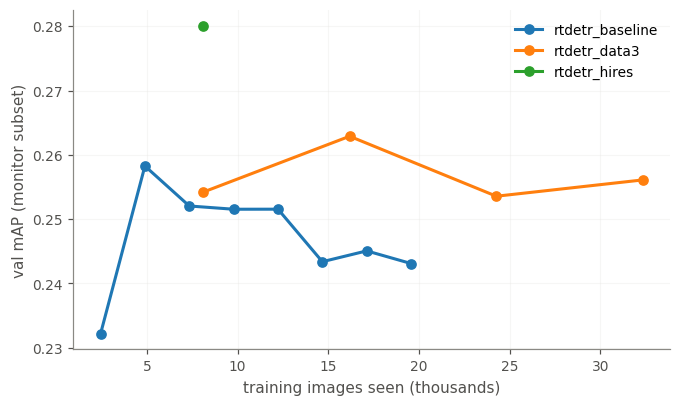

In [9]:
# Val mAP on the monitor subset after each epoch, by images seen (epochs differ in length between the runs)
hists = {"rtdetr_baseline": pd.read_csv(REPO_ROOT / "results" / "runs" / "rtdetr_baseline" / "history.csv")}
hists.update({r: run.history for r, run in runs.items() if len(run.history)})
n_train = {"rtdetr_baseline": len(train10)}
fig, ax = plt.subplots(figsize=(7, 4))
for r, h in hists.items():
    seen = (h.epoch + 1) * n_train.get(r, len(train3)) / 1000
    ax.plot(seen, h.val_mAP, marker="o", label=r)
ax.set_xlabel("training images seen (thousands)")
ax.set_ylabel("val mAP (monitor subset)")
ax.legend()
ax.grid(alpha=0.3)
save_fig(fig, "rtdetr_scaled_curves", P)
plt.show()

In [10]:
# Status of every run, time used, distinct warnings logged in this session (should be empty)
print(f"session: {(time.time() - NOTEBOOK_START) / 3600:.2f} h of {SESSION_HOURS} h")
print({r: list(run.stages) for r, run in runs.items()})
env.warnings_summary(P)

session: 3.86 h of 5.0 h
{'rtdetr_data3': ['train', 'eval_val', 'test'], 'rtdetr_hires': []}


[]